In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.dates import DateFormatter
import os
import math

import sys
sys.path.append('../bgc-processing')

from navis_processing.calc_sensor import pH_sbe, o2_sbe, mcoms
from argodb.api import get_cal

pd.set_option('display.max_rows', 200)

In [3]:
root = r"data\mcoms"
files = [x for x in os.listdir(root) if x.endswith(".pkl")]
files

['F1358_20220415.pkl']

In [4]:
data = pd.DataFrame(columns=['SN','DATE','MCOMS1','MCOMS2','MCOMS3'])

for file in files:
    data = data.append(pd.read_pickle(root+'/'+file))
data = data.sort_values('DATE')
data['DATE'] = data['DATE'].dt.round('1s')
data = data.reset_index()

print(data)

data["MCOMS1"] = data["MCOMS1"].astype(int)
data["MCOMS2"] = data["MCOMS2"].astype(int)
data["MCOMS3"] = pd.to_numeric(data["MCOMS3"])

    index    SN                DATE MCOMS1 MCOMS2 MCOMS3
0       0  1358 2022-04-15 09:15:00    147  50850    499
1       1  1358 2022-04-15 09:30:00    145  50790    490
2       2  1358 2022-04-15 09:45:01    143  50810    498
3       3  1358 2022-04-15 10:00:00    139  50970    501
4       4  1358 2022-04-15 10:15:01    142  51050    506
5       5  1358 2022-04-15 10:30:00    143  51000    505
6       6  1358 2022-04-15 10:45:00    145  50940    514
7       7  1358 2022-04-15 11:00:01    145  50970    512
8       8  1358 2022-04-15 11:15:00    143  50960    510
9       9  1358 2022-04-15 11:30:01    144  50890    506
10     10  1358 2022-04-15 11:45:01    144  50890    507
11     11  1358 2022-04-15 12:00:00    142  50890    505
12     12  1358 2022-04-15 12:15:01    147  50850    505
13     13  1358 2022-04-15 12:30:01    143  50810    509
14     14  1358 2022-04-15 12:45:00    146  50800    504
15     15  1358 2022-04-15 13:00:01    147  50760    506
16     16  1358 2022-04-15 13:1

In [5]:
data = data.set_index("DATE")

In [6]:
cal = get_cal("1358",'NAVIS_EBR')
print(cal['FLUOROMETER_CDOM']['PREDEPLOYMENT_CALIB_COEFFICIENT']['DARK_CDOM'])

#, 'FLUOROMETER_CHLA', 'BACKSCATTERINGMETER_BBP700',

50


In [7]:
for sn in data.SN.unique():
    print(sn)
    cal = get_cal(sn,'NAVIS_EBR')

    print(cal['FLUOROMETER_CDOM']['PREDEPLOYMENT_CALIB_COEFFICIENT'])
    
    sub = data.loc[data.SN == sn,:]

    #MCOMS1
    data.loc[data.SN==sn, 'CHLA'] = mcoms(cal['FLUOROMETER_CHLA']['PREDEPLOYMENT_CALIB_COEFFICIENT']['SCALE_CHLA'],
        cal['FLUOROMETER_CHLA']['PREDEPLOYMENT_CALIB_COEFFICIENT']['DARK_CHLA'],
        sub.MCOMS1)

    #MCOMS2
    data.loc[data.SN==sn, 'BBP'] = mcoms(cal['BACKSCATTERINGMETER_BBP700']['PREDEPLOYMENT_CALIB_COEFFICIENT']['SCALE_BACKSCATTERING700'],
        cal['BACKSCATTERINGMETER_BBP700']['PREDEPLOYMENT_CALIB_COEFFICIENT']['DARK_BACKSCATTERING700'],
        sub.MCOMS2)

    #MCOMS3
    data.loc[data.SN==sn, 'CDOM'] = mcoms(cal['FLUOROMETER_CDOM']['PREDEPLOYMENT_CALIB_COEFFICIENT']['SCALE_CDOM'],
        cal['FLUOROMETER_CDOM']['PREDEPLOYMENT_CALIB_COEFFICIENT']['DARK_CDOM'],
        sub.MCOMS3)

print(data.head())

1358
{'DARK_CDOM': 50, 'SCALE_CDOM': 0.007968}
                     index    SN  MCOMS1  MCOMS2  MCOMS3      CHLA       BBP  \
DATE                                                                           
2022-04-15 09:15:00      0  1358     147   50850     499  0.169362  0.018324   
2022-04-15 09:30:00      1  1358     145   50790     490  0.165870  0.018302   
2022-04-15 09:45:01      2  1358     143   50810     498  0.162378  0.018309   
2022-04-15 10:00:00      3  1358     139   50970     501  0.155394  0.018367   
2022-04-15 10:15:01      4  1358     142   51050     506  0.160632  0.018396   

                         CDOM  
DATE                           
2022-04-15 09:15:00  3.577632  
2022-04-15 09:30:00  3.505920  
2022-04-15 09:45:01  3.569664  
2022-04-15 10:00:00  3.593568  
2022-04-15 10:15:01  3.633408  


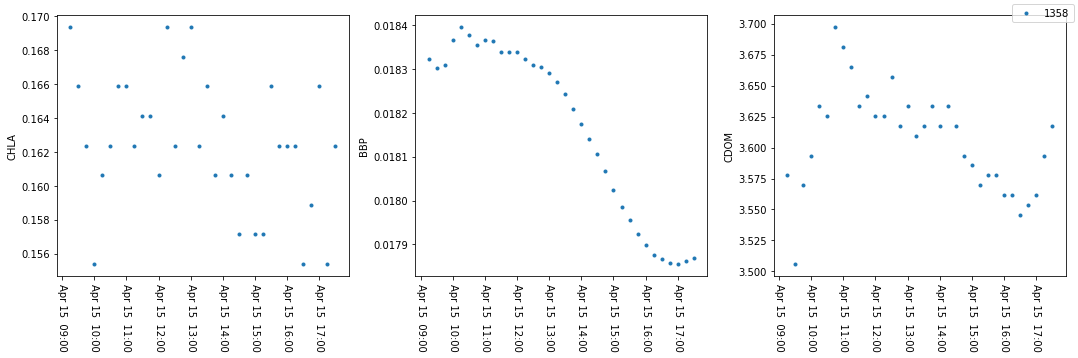

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(15, 5)) #Create figure

#Add trace for each float and variable
sns = data.SN.unique()

for i, var in enumerate(['CHLA','BBP','CDOM']):
    for sn in sns:
        col = i%3
        row = math.floor(i/3)

        sub = data.loc[data.SN == sn]
        axs[col].plot(sub.index, sub[var], marker=".", linestyle='None')

        #Formatting
        axs[col].set_ylabel(var)
        dateFormat = DateFormatter("%b %d  %H:%M")
        axs[col].xaxis.set_major_formatter(dateFormat)
        axs[col].tick_params(axis='x', rotation=-90)
        fig.tight_layout()
        
fig.legend(sns)